# Project 2: Housing Price Prediction – Pass 11

## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

Statement:

We want to predict housing sale prices based on various correlated feature data. This is a *supervised regression* problem, where the target of the prediction is sales prices. To accomplish this, we use a regression model alongside Regression prediction techniques, as well as feature scaling and regularization to minimize the RMS percentage error.

## Data Collection/Sources


Data Collection describes the process by which we obtain the data for use in the project. In this case, our data comes from S3 storage buckets on AWS, which we load into memory (variables) via URLs by passing them to the read_csv function of the pandas python library (more on that soon).

The data comes in one large set containing the full data available for use in the project. It is supplemented by a data dictionary that describes the set, the data types of the included data, and other information relevant to its use.

Finally, to store the data in a form we can work with in memory, we use a storage structure called a DataFrame object from the pandas python library. This object allows us to quickly view the data and preview operations on the data without changing it, as well as make updates to the data in a highly intuitive way.

First, load Pandas, Numpy, and Matplotlib modules:

In [71]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

Load data Train.csv from AWS S3:

In [72]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

Next, make a preview DataFrame to look at columns:

In [73]:
# make preview
df_preview = pd.read_csv(url, nrows=1)
df_preview

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400


In [74]:
# preview all column names
df_preview.columns

Index(['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish'

Define the target column (and features types, if required):

In [75]:
# define target column (by name) and target features type
target_col = 'SalePrice'
feature_types = ['float64', 'int64']

Create list of target col and feature cols:

In [76]:
# use list comprehension to generate list of target col + selected feature cols
selected_cols = [
    col
    for col in df_preview.columns
    if (col == target_col) or (df_preview[col].dtype in feature_types)
]
selected_cols

['PID',
 'MS SubClass',
 'Lot Frontage',
 'Lot Area',
 'Alley',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Mas Vnr Type',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Fireplace Qu',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Pool QC',
 'Misc Feature',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

Read in the data from .csv using target_col and feature_types:

In [77]:
# make dataframe
df = pd.read_csv( url, usecols=selected_cols )

Finally, check the dataframe:

In [78]:
# check dataframe
df

,PID,MS SubClass,Lot Frontage,Lot Area,Alley,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Type,...,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Misc Feature,Misc Val,Mo Sold,Yr Sold,SalePrice
0,905101070,20,62.0,14299,NaN,4,3,1964,1964,NaN,...,0,0,0,0,NaN,NaN,0,7,2007,115400
1,905101330,90,72.0,10791,NaN,4,5,1967,1967,NaN,...,0,0,0,0,NaN,Shed,500,10,2006,90000
2,903454090,50,50.0,9000,NaN,6,6,1937,1950,NaN,...,0,0,126,0,NaN,NaN,0,12,2007,141000
3,533244030,60,68.0,7379,NaN,8,5,2000,2000,NaN,...,0,0,0,0,NaN,NaN,0,4,2010,254000
4,909252020,70,60.0,7200,NaN,7,9,1936,2007,NaN,...,0,0,0,0,NaN,NaN,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,52.0,6240,NaN,6,6,1934,1950,NaN,...,0,0,0,0,NaN,Shed,400,9,2006,114500
2633,906201021,80,74.0,10778,NaN,7,6,1990,1991,NaN,...,0,0,0,0,NaN,NaN,0,7,2009,162000
2634,533253070,120,61.0,3782,NaN,8,5,1981,1981,NaN,...,0,0,0,0,NaN,NaN,0,9,2009,211500
2635,527376100,20,78.0,10140,NaN,6,5,1974,1974,BrkFace,...,0,0,0,0,NaN,NaN,0,8,2009,165000


In [79]:
# use list comprehension to generate list of target col + selected feature cols
selected_cols = [
    col
    for col in df.columns
    if (col == target_col) or (df[col].dtype in feature_types)
]
selected_cols

['PID',
 'MS SubClass',
 'Lot Frontage',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

In [80]:
# make dataframe
df = pd.read_csv( url, usecols=selected_cols )

In [81]:
# check dataframe
df

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,905101070,20,62.0,14299,4,3,1964,1964,0.0,513.0,...,0,0,0,0,0,0,0,7,2007,115400
1,905101330,90,72.0,10791,4,5,1967,1967,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,903454090,50,50.0,9000,6,6,1937,1950,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,533244030,60,68.0,7379,8,5,2000,2000,0.0,484.0,...,280,184,0,0,0,0,0,4,2010,254000
4,909252020,70,60.0,7200,7,9,1936,2007,0.0,350.0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,52.0,6240,6,6,1934,1950,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,906201021,80,74.0,10778,7,6,1990,1991,0.0,460.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,533253070,120,61.0,3782,8,5,1981,1981,0.0,960.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,527376100,20,78.0,10140,6,5,1974,1974,174.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000


## Data Cleaning


Data Cleaning is the process of preparing the data set for use in analysis. Many data sets contain bad or null (empty) values, which can cause errors when trying to work with the data and use it in code. Cleaning the data involves removing bad (null-containing) columns and/or rows from the set, as well as imputing (replacing via insertion) similar data into fields with missing or unusable values.

Here, to clean the data, we mostly use the pandas drop function included with pandas DataFrame objects, which allow us to drop columns and rows according to conditions we specify, much like SQL WHERE clauses.

#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



- head

In [82]:
# head
df.head()

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,905101070,20,62.0,14299,4,3,1964,1964,0.0,513.0,...,0,0,0,0,0,0,0,7,2007,115400
1,905101330,90,72.0,10791,4,5,1967,1967,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,903454090,50,50.0,9000,6,6,1937,1950,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,533244030,60,68.0,7379,8,5,2000,2000,0.0,484.0,...,280,184,0,0,0,0,0,4,2010,254000
4,909252020,70,60.0,7200,7,9,1936,2007,0.0,350.0,...,256,0,0,0,0,0,0,4,2009,155000


- tail

In [83]:
# tail
df.tail()

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
2632,903231070,50,52.0,6240,6,6,1934,1950,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,906201021,80,74.0,10778,7,6,1990,1991,0.0,460.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,533253070,120,61.0,3782,8,5,1981,1981,0.0,960.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,527376100,20,78.0,10140,6,5,1974,1974,174.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000
2636,528292060,60,41.0,12460,7,5,1999,2000,0.0,870.0,...,144,44,0,0,0,0,0,5,2008,225000


- shape

In [84]:
# shape
df.shape

(2637, 38)

- size

In [85]:
# size
df.size

100206

- info

In [86]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 38 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   Lot Frontage     2188 non-null   float64
 3   Lot Area         2637 non-null   int64  
 4   Overall Qual     2637 non-null   int64  
 5   Overall Cond     2637 non-null   int64  
 6   Year Built       2637 non-null   int64  
 7   Year Remod/Add   2637 non-null   int64  
 8   Mas Vnr Area     2614 non-null   float64
 9   BsmtFin SF 1     2636 non-null   float64
 10  BsmtFin SF 2     2636 non-null   float64
 11  Bsmt Unf SF      2636 non-null   float64
 12  Total Bsmt SF    2636 non-null   float64
 13  1st Flr SF       2637 non-null   int64  
 14  2nd Flr SF       2637 non-null   int64  
 15  Low Qual Fin SF  2637 non-null   int64  
 16  Gr Liv Area      2637 non-null   int64  
 17  Bsmt Full Bath

- describe

In [87]:
# describe
df.describe()

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2.637000e+03,2637.000000,2188.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2614.000000,2636.000000,...,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000
mean,7.141301e+08,57.349261,69.166819,10044.694729,6.097459,5.569966,1971.288586,1984.202882,101.887911,438.441199,...,94.305271,46.984452,22.813424,2.368601,15.775123,2.130072,42.014031,6.243838,2007.795601,179986.230186
std,1.887527e+08,42.499091,23.356779,6742.549521,1.411522,1.118262,30.306986,20.913077,179.578232,449.602326,...,126.927272,66.564333,61.177638,23.160600,55.783751,35.140140,393.158781,2.722093,1.306403,78309.251522
min,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,5.284770e+08,20.000000,58.000000,7436.000000,5.000000,5.000000,1954.000000,1965.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,5.354530e+08,50.000000,68.000000,9450.000000,6.000000,5.000000,1973.000000,1993.000000,0.000000,368.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,9.071870e+08,70.000000,80.000000,11526.000000,7.000000,6.000000,2001.000000,2004.000000,164.000000,732.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213000.000000
max,1.007100e+09,190.000000,313.000000,164660.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,1424.000000,742.000000,584.000000,407.000000,576.000000,800.000000,12500.000000,12.000000,2010.000000,745000.000000


- nunique

In [88]:
# nunique
df.nunique().sort_values( ascending = False )

,0
PID,2637
Lot Area,1799
Gr Liv Area,1216
Bsmt Unf SF,1080
1st Flr SF,1022
Total Bsmt SF,1001
SalePrice,983
BsmtFin SF 1,935
2nd Flr SF,589
Garage Area,576


In [89]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
Total Bsmt SF,37.959803
SalePrice,37.277209
BsmtFin SF 1,35.456959
2nd Flr SF,22.335988
Garage Area,21.843003


- unique

In [90]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [91]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Half Bath,2
Bsmt Full Bath,2
Total Bsmt SF,1
Garage Cars,1
Garage Area,1
Bsmt Unf SF,1
BsmtFin SF 1,1


In [92]:
# percent null by column
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Lot Frontage,17.026925
Garage Yr Blt,5.574516
Mas Vnr Area,0.872203
Bsmt Half Bath,0.075844
Bsmt Full Bath,0.075844
Total Bsmt SF,0.037922
Garage Cars,0.037922
Garage Area,0.037922
Bsmt Unf SF,0.037922
BsmtFin SF 1,0.037922


In [93]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([17.02692454,  5.5745165 ,  0.87220326,  0.07584376,  0.03792188,
        0.        ])

In [94]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(629)

In [95]:
# how many rows with at least one null
num_rows_with_nulls = df.isna().any(axis=1).sum()
int(num_rows_with_nulls)

604

Many different null counts exist throughout the data set, indicating that this will not be a straightforward nulls cleanup.

- dtypes

In [96]:
# dtypes
df.dtypes

,0
PID,int64
MS SubClass,int64
Lot Frontage,float64
Lot Area,int64
Overall Qual,int64
Overall Cond,int64
Year Built,int64
Year Remod/Add,int64
Mas Vnr Area,float64
BsmtFin SF 1,float64


Examine null columns, columns with some nulls, and columns with no nulls:

In [97]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [98]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [99]:
# show columns with some null values
df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].sort_values( ascending = False )

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Half Bath,2
Bsmt Full Bath,2
BsmtFin SF 1,1
BsmtFin SF 2,1
Total Bsmt SF,1
Bsmt Unf SF,1
Garage Cars,1


In [100]:
# count these
int(df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].count())

11

In [101]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
PID,0
MS SubClass,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
1st Flr SF,0
2nd Flr SF,0
Low Qual Fin SF,0


In [102]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 0].count())

27

#### Target: Value Counts

In [103]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [104]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [105]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [106]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

In [107]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

There are no nulls in the target column, which means no rows will need to be dropped on its account.

#### Summary:

The floats+ints-feature dataset contains 2637 rows and 38 columns, making for a total of 100206 entries of data. Many of these fields are null.

Details:

  - target column: 'SalePrice'
  - feature columns: [
       'Lot Frontage', 'Garage Yr Blt', 'Mas Vnr Area', 'Bsmt Full Bath',
       'Bsmt Half Bath', 'BsmtFin SF 2', 'BsmtFin SF 1', 'Total Bsmt SF',
       'Bsmt Unf SF', 'Garage Area', 'Garage Cars',
       'MS SubClass', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold'
       ]
  - identifier columns: 'PID'
  - null columns: 0
  - null rows (target): 0
  - null rows (any): 2637 (100%)

#### If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


First, make a backup:

In [108]:
# make backup
df_bak = df.copy()

In [109]:
# restore from backup
df = df_bak.copy()

In [110]:
# df again to double-check
df

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,905101070,20,62.0,14299,4,3,1964,1964,0.0,513.0,...,0,0,0,0,0,0,0,7,2007,115400
1,905101330,90,72.0,10791,4,5,1967,1967,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,903454090,50,50.0,9000,6,6,1937,1950,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,533244030,60,68.0,7379,8,5,2000,2000,0.0,484.0,...,280,184,0,0,0,0,0,4,2010,254000
4,909252020,70,60.0,7200,7,9,1936,2007,0.0,350.0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,52.0,6240,6,6,1934,1950,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,906201021,80,74.0,10778,7,6,1990,1991,0.0,460.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,533253070,120,61.0,3782,8,5,1981,1981,0.0,960.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,527376100,20,78.0,10140,6,5,1974,1974,174.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000


1. Remove identifier columns

In [111]:
# remove identifier columns from DataFrame
df = df.drop( columns = [ 'PID' ] )

In [112]:
# backup 1
df_bak1 = df.copy()

In [113]:
# restore from backup 1
df = df_bak1.copy()

In [114]:
df

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,0,0,0,0,0,0,0,7,2007,115400
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,280,184,0,0,0,0,0,4,2010,254000
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000


2. Drop null target rows



- No null target rows

3. Drop feature columns with many or all nulls

In [115]:
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2
Garage Cars,1
Garage Area,1
Bsmt Unf SF,1
BsmtFin SF 1,1
Total Bsmt SF,1


In [116]:
# df = df.loc[:, df.isnull().mean() <= 0.5]
df = df.drop( columns = [index for index in list(df.isnull().sum().index) if (df.isnull().sum().loc[index] / df.shape[0] > 0.4)])

In [117]:
df

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,0,0,0,0,0,0,0,7,2007,115400
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,280,184,0,0,0,0,0,4,2010,254000
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000


In [118]:
list(df.isnull().sum().index)

['MS SubClass',
 'Lot Frontage',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

In [119]:
df.shape

(2637, 37)

4. Drop remaining records with null counts (if few)

In [120]:
# backup 2
df_bak2 = df.copy()

In [121]:
# restore from backup 2
df = df_bak2.copy()

In [122]:
df

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,0,0,0,0,0,0,0,7,2007,115400
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,280,184,0,0,0,0,0,4,2010,254000
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000


In [123]:
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2
Garage Cars,1
Garage Area,1
Bsmt Unf SF,1
BsmtFin SF 1,1
Total Bsmt SF,1


In [124]:
df = df.dropna(subset=[index for index in list(df.isnull().sum().index) if (df.isnull().sum().loc[index] / df.shape[0] < 0.05)])

In [125]:
df

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,0,0,0,0,0,0,0,7,2007,115400
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,280,184,0,0,0,0,0,4,2010,254000
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000


In [126]:
list(df.isnull().sum().index)

['MS SubClass',
 'Lot Frontage',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

In [127]:
df.shape

(2611, 37)

5.  impute with the median for remaining fields

In [128]:
# backup 3
df_bak3 = df.copy()

In [129]:
# restore from backup 3
df = df_bak3.copy()

In [130]:
df

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,0,0,0,0,0,0,0,7,2007,115400
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,280,184,0,0,0,0,0,4,2010,254000
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000


In [131]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,443
Garage Yr Blt,145
MS SubClass,0
Overall Qual,0
Lot Area,0
Overall Cond,0
Year Built,0
Mas Vnr Area,0
Year Remod/Add,0
BsmtFin SF 2,0


In [132]:
# normalize null counts (per column)
df.isnull().sum().sort_values( ascending = False ) / df.shape[0] * 100

,0
Lot Frontage,16.966679
Garage Yr Blt,5.553428
MS SubClass,0.000000
Overall Qual,0.000000
Lot Area,0.000000
Overall Cond,0.000000
Year Built,0.000000
Mas Vnr Area,0.000000
Year Remod/Add,0.000000
BsmtFin SF 2,0.000000


Impute:

In [133]:
feature_cols = list(df.drop(columns = target_col).columns)
feature_cols

['MS SubClass',
 'Lot Frontage',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold']

In [134]:
# loop through features to bulk impute with respective column medians
for feature_col in feature_cols:

  # Calculate the median
  median = df[feature_col].median()
  print(median)

  # Assign median to nulls
  df.fillna( {feature_col: median}, inplace = True )

  # Verify median is about the same as before
  print(df[feature_col].median())

50.0
50.0
68.0
68.0
9434.0
9434.0
6.0
6.0
5.0
5.0
1973.0
1973.0
1993.0
1993.0
0.0
0.0
368.0
368.0
0.0
0.0
463.0
463.0
988.0
988.0
1082.0
1082.0
0.0
0.0
0.0
0.0
1440.0
1440.0
0.0
0.0
0.0
0.0
2.0
2.0
0.0
0.0
3.0
3.0
1.0
1.0
6.0
6.0
1.0
1.0
1979.0
1979.0
2.0
2.0
478.0
478.0
0.0
0.0
27.0
27.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
6.0
6.0
2008.0
2008.0


In [135]:
df

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,0,0,0,0,0,0,0,7,2007,115400
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,280,184,0,0,0,0,0,4,2010,254000
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000


In [136]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
MS SubClass,0
Lot Frontage,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
Mas Vnr Area,0
BsmtFin SF 1,0
BsmtFin SF 2,0


In [137]:
# backup 4
df_bak4 = df.copy()

In [138]:
# restore from backup 4
df = df_bak4.copy()

In [139]:
df

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,0,0,0,0,0,0,0,7,2007,115400
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,0,0,0,0,0,0,500,10,2006,90000
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,0,162,0,0,126,0,0,12,2007,141000
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,280,184,0,0,0,0,0,4,2010,254000
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,112,0,0,0,0,0,400,9,2006,114500
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,114,36,0,0,0,0,0,7,2009,162000
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,133,78,0,0,0,0,0,9,2009,211500
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,0,0,0,0,0,0,0,8,2009,165000


In [140]:
# check total null counts sum
f"Number of remaining nulls in df: {int(df.isnull().sum().sum())}"

'Number of remaining nulls in df: 0'

## Exploratory Data Analysis


In [141]:
len(df.columns)

37

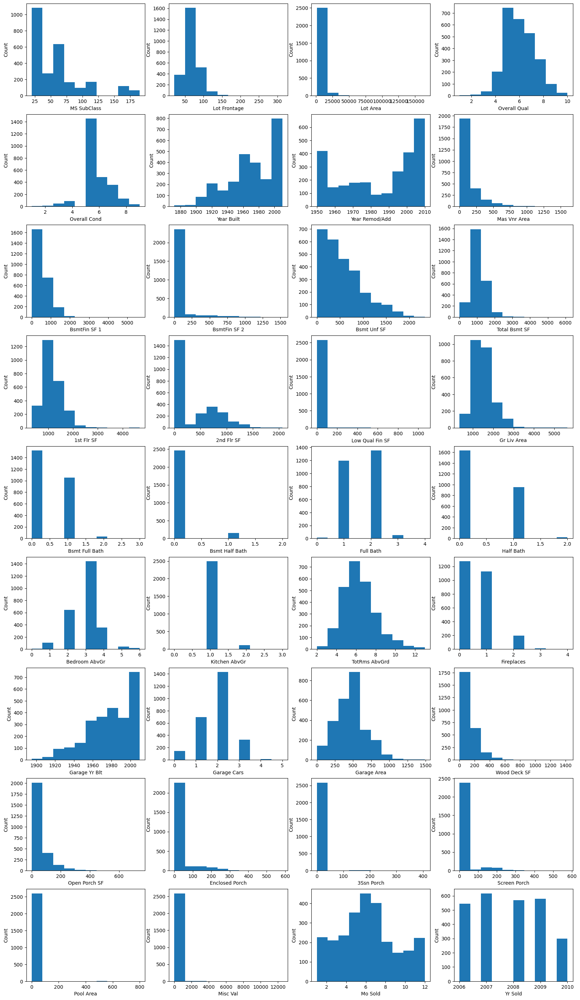

In [142]:
# Let's plot mpg and all of our predictors
subplots_per_row = 4
total_subplots = len(df.columns)
row_count = total_subplots // subplots_per_row
fig, subplots = plt.subplots(row_count,subplots_per_row, figsize = (20,4*row_count)) # Creating 2x4 subplots because we have 8 columns in our data
column_names = df.columns

subplots = subplots.flatten()[:len(column_names)]  # flatten and slice axs
for n, subplot in enumerate(subplots):             # Loop through axs
  subplot.hist(df[column_names[n]])
  subplot.set_xlabel(column_names[n])
  subplot.set_ylabel('Count')

### What do we notice?

- SalePrice and Lot Frontage are positively skewed
- All float features look positively skewed
- Some features appear categorical (only a few unique values per feature)
- Perhaps some outliers
- For int columns, some features are positively skewed, others negatively skewed, and a couple are evenly distributed
- Lots of positively skewed features (almost look categorical)
- Some features appear categorical (only a few unique values per feature)
- Perhaps some outliers (see positively skewed point above)

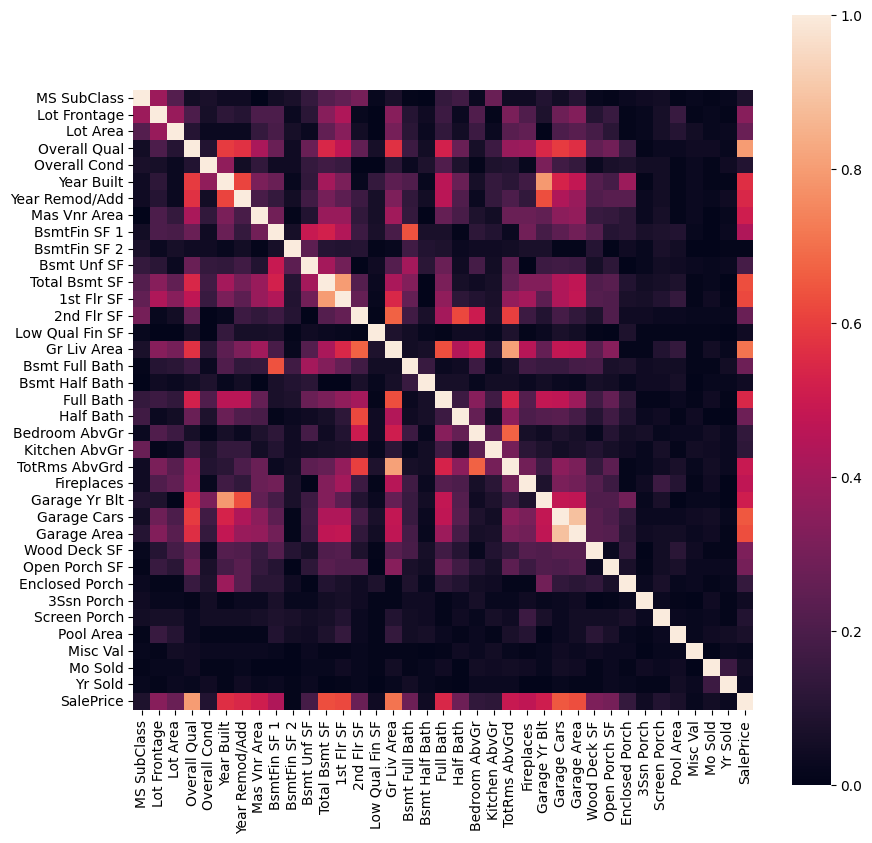

In [143]:
# Correlation plot — target and features
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;



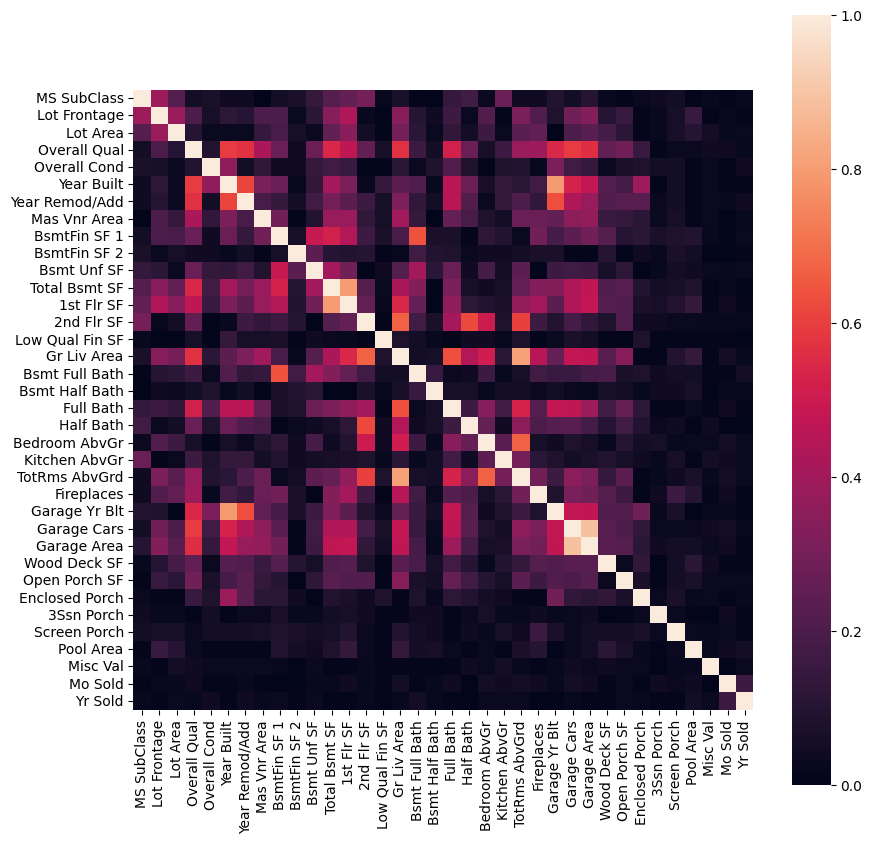

In [144]:
# Correlation plot — features only
plt.figure(figsize=(10,10))
correlation_matrix = df.drop( columns = [target_col] ).corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;



In [145]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Overall Qual,0.80
Gr Liv Area,0.71
Garage Cars,0.65
Total Bsmt SF,0.63
Garage Area,0.63
1st Flr SF,0.62
Year Built,0.56
Full Bath,0.54
Year Remod/Add,0.54


<Axes: >

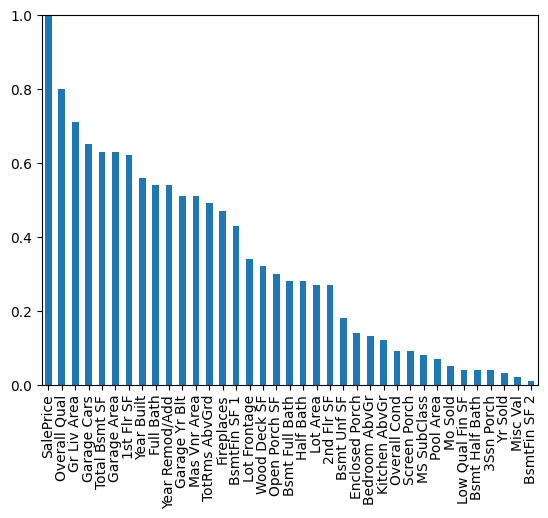

In [146]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [147]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()

,level_0,level_1,0
0,MS SubClass,MS SubClass,1.00
1,MS SubClass,Lot Frontage,0.39
2,MS SubClass,Lot Area,0.22
3,MS SubClass,Overall Qual,0.05
4,MS SubClass,Overall Cond,0.07
...,...,...,...
1364,SalePrice,Pool Area,0.07
1365,SalePrice,Misc Val,0.02
1366,SalePrice,Mo Sold,0.05
1367,SalePrice,Yr Sold,0.03


In [148]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,MS SubClass,Lot Frontage,0.39
1,MS SubClass,Lot Area,0.22
2,MS SubClass,Overall Qual,0.05
3,MS SubClass,Overall Cond,0.07
4,MS SubClass,Year Built,0.04
...,...,...,...
1327,SalePrice,Screen Porch,0.09
1328,SalePrice,Pool Area,0.07
1329,SalePrice,Misc Val,0.02
1330,SalePrice,Mo Sold,0.05


In [149]:
corrs.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Garage Area,Garage Cars,0.89
1,Garage Cars,Garage Area,0.89
2,TotRms AbvGrd,Gr Liv Area,0.81
3,Gr Liv Area,TotRms AbvGrd,0.81
4,Total Bsmt SF,1st Flr SF,0.80
...,...,...,...
1327,Mas Vnr Area,MS SubClass,0.00
1328,Yr Sold,Fireplaces,0.00
1329,Yr Sold,Half Bath,0.00
1330,Bsmt Half Bath,1st Flr SF,0.00


In [150]:
corrs.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Garage Area,Garage Cars,0.89
1,TotRms AbvGrd,Gr Liv Area,0.81
2,Total Bsmt SF,1st Flr SF,0.80
3,Overall Qual,SalePrice,0.80
4,Year Built,Garage Yr Blt,0.79
...,...,...,...
661,Mo Sold,Misc Val,0.00
662,Yr Sold,Low Qual Fin SF,0.00
663,Mas Vnr Area,Bsmt Half Bath,0.00
664,Yr Sold,Fireplaces,0.00


### What do we notice?

- SalePrice vs. Lot Frontage do not appear to be highly correlated to each other
- BsmtFin SF 2 and Bsmt Half Bath are very independent from most other features, but also poorly coorelate with SalePrice
- Garage Area and Garage Cars coorelate with target well and each other fairly well, but don't correlate with other features nearly as much, meaning one of these could be a good candidate

- SalePrice correlated with General living area, first floor sf, year built, and overall quality
- lattice pattern: typically, if a feature doesn't correlate with other features, it also doesn't correlate with the target

In [151]:
df.size

96607

In [152]:
# Let's plot a pairplot
sns.pairplot(df) ;



### What do we notice?

- SalePrice vs. Lot Frontage is rather scattered, and does not appear to be linear.
- Many scattered relationships, some with some degree of potential linearity
- Not as many non-categorical scatter plots
- some linear-looking trends, including general living area and overall quality (i.e., they highly correlate with the target, and have linear-looking plot clustering)

## Processing



### Prepare data frame

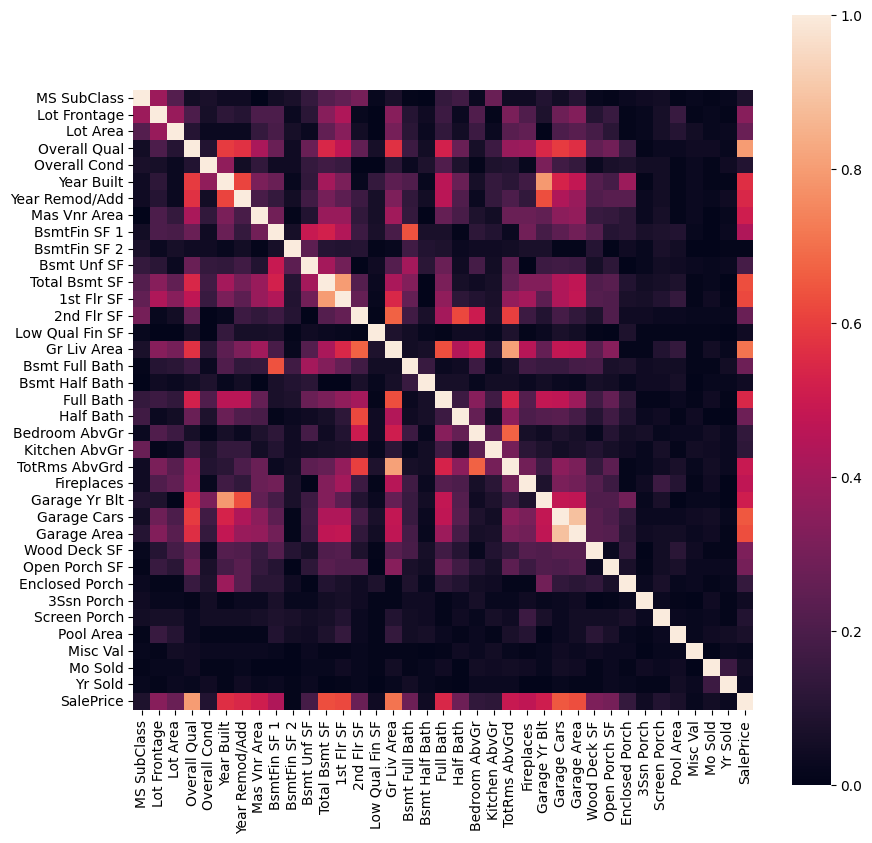

In [154]:
# Correlation plot — target and features (again)
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;



Here, we can make a few notes about the best features:
- BsmtFin SF 2 and Bsmt Half Bath are quite non-correlated with SalePrice (0.01 and 0.04, respectively), so we can safely exclude them
- Bsmt Unf SF, Bsmt Full Bath, and Lot Frontage are all weakly correlated (0.18, 0.28, and 0.34), but should be kept for now
- Garage Cars and Garage Area are strongly correlated with each other, so only one of these should be kept
- Everything else looks sufficiently independent that they may be kept

In [184]:
# use threshold value to drop features that are statistical noise
threshold_val = 0.05
drop_cols_threshold = [col for col in df.columns if correlation_matrix[target_col].abs().loc[col] < threshold_val]

In [185]:
# list of redundants
redundants = ['Garage Area', 'TotRms AbvGrd', 'Garage Yr Blt', 'Total Bsmt SF']

In [186]:
target_col = 'SalePrice'
drop_cols = drop_cols_threshold + redundants + [target_col]

In [187]:
target_col = 'SalePrice'
feature_cols = list( df.drop( columns = drop_cols ) )
target_col, feature_cols, drop_cols

('SalePrice',
 ['MS SubClass',
  'Lot Frontage',
  'Lot Area',
  'Overall Qual',
  'Overall Cond',
  'Year Built',
  'Year Remod/Add',
  'Mas Vnr Area',
  'BsmtFin SF 1',
  'Bsmt Unf SF',
  '1st Flr SF',
  '2nd Flr SF',
  'Gr Liv Area',
  'Bsmt Full Bath',
  'Full Bath',
  'Half Bath',
  'Bedroom AbvGr',
  'Kitchen AbvGr',
  'Fireplaces',
  'Garage Cars',
  'Wood Deck SF',
  'Open Porch SF',
  'Enclosed Porch',
  'Screen Porch',
  'Pool Area',
  'Mo Sold'],
 ['BsmtFin SF 2',
  'Low Qual Fin SF',
  'Bsmt Half Bath',
  '3Ssn Porch',
  'Misc Val',
  'Yr Sold',
  'Garage Area',
  'TotRms AbvGrd',
  'Garage Yr Blt',
  'Total Bsmt SF',
  'SalePrice'])

In [188]:
# Split data frame into target and features
target   = df[target_col].copy()
features = df[feature_cols].copy()

In [189]:
# Verify features
features

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,Bsmt Unf SF,...,Bedroom AbvGr,Kitchen AbvGr,Fireplaces,Garage Cars,Wood Deck SF,Open Porch SF,Enclosed Porch,Screen Porch,Pool Area,Mo Sold
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,348.0,...,3,1,0,2.0,0,0,0,0,0,7
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,2,2,0,2.0,0,0,0,0,0,10
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,780.0,...,3,1,1,1.0,0,162,0,126,0,12
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,491.0,...,3,1,1,2.0,280,184,0,0,0,4
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,0.0,...,3,1,0,2.0,256,0,0,0,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,816.0,...,3,1,1,2.0,112,0,0,0,0,9
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,308.0,...,1,1,0,2.0,114,36,0,0,0,7
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,266.0,...,1,1,2,2.0,133,78,0,0,0,9
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,1064.0,...,3,1,1,2.0,0,0,0,0,0,8


In [190]:
# Verify target
target

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [191]:
type(features), features.shape, features.ndim

(pandas.core.frame.DataFrame, (2611, 26), 2)

In [192]:
type(target), target.shape, target.ndim

(pandas.core.series.Series, (2611,), 1)

### Fit & Assess Our Model

#### Linear Regression — Sklearn

Now, we perform a linear regression using sklearn:

In [193]:
# First we run a single split (single holdout) to see what the data looks like:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size = 0.2, random_state=42)

In [194]:
# Fit a linear model using Sklearn
model = LinearRegression()
model.fit(X_train, y_train)

( model.intercept_, model.coef_ )

(np.float64(-1250375.9532020076),
 array([-1.66220808e+02, -1.12759344e+01,  2.92815143e-01,  1.74701815e+04,
         3.85895593e+03,  3.67858334e+02,  2.39610215e+02,  3.66458821e+01,
         1.74964092e+01,  5.75524620e+00,  1.52916047e+01,  1.14039829e+01,
         5.03271040e+01,  8.37216593e+03,  4.42012925e+02, -5.38050103e+03,
        -6.63113636e+03, -8.12116299e+03,  2.93292939e+03,  9.31680832e+03,
         2.48883051e+01, -1.43088140e+01,  2.51134747e+01,  4.93757734e+01,
        -4.51745907e+01,  1.61976181e+02]))

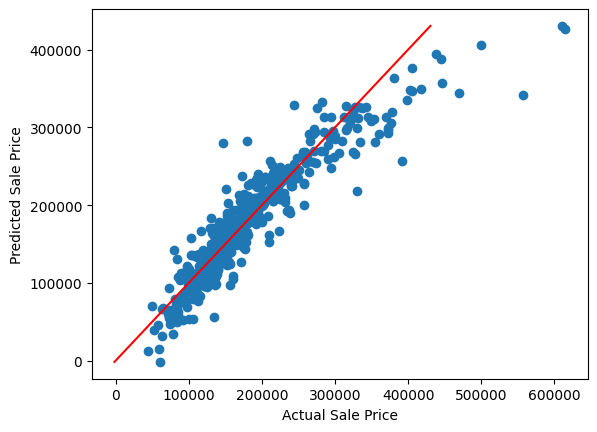

In [195]:
# See how well our model performs on our test data
y_pred = model.predict(X_test)
plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)],[min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price') ;

In [196]:
list(zip(y_test,y_pred))[:10]

[(109000, np.float64(135100.56745560095)),
 (112000, np.float64(95449.24818195449)),
 (193879, np.float64(205633.02045610477)),
 (266000, np.float64(282645.9415140122)),
 (376162, np.float64(305144.1258682243)),
 (223500, np.float64(166849.70399718708)),
 (270000, np.float64(255335.80198058137)),
 (137000, np.float64(113084.37762855925)),
 (392000, np.float64(257014.68791703111)),
 (137500, np.float64(131090.18412842066))]

We'll use RMSE as our performance metric.

In [197]:
# Calculate root mean squared error on test data
rmse = metrics.mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse}")

RMSE: 31606.37604506065


Corroborate using cross_val_score (Single CV):

In [198]:
# Use cross validation (k-fold) to assess model performance (Single CV — Single run of a K-Fold loop)
results_cvs = cross_val_score(model, features, target, scoring='neg_root_mean_squared_error', cv = 10)
rmse_cvs = abs(results_cvs.mean())
print(f"CV RMSE: {rmse_cvs}")

CV RMSE: 31983.486408833018


## Data Visualization/Communication of Results


### Residual Analysis

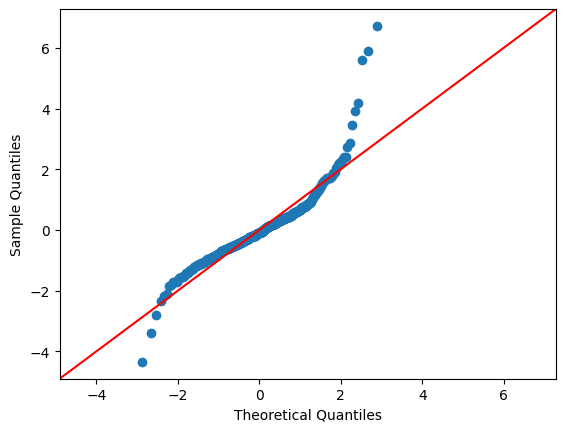

In [199]:
# QQ Plot - Residuals are normally distributed
res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

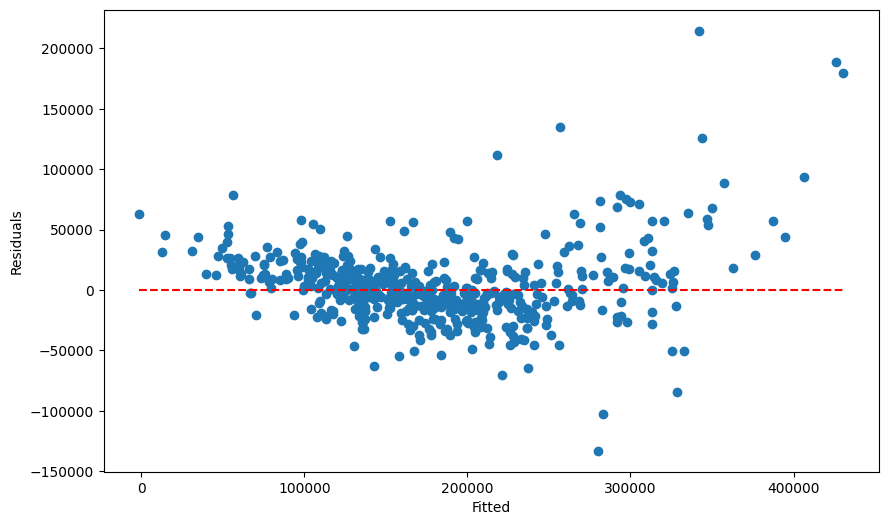

In [200]:
# Residuals vs Fitted (Predicted) Values - Constant variance
plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

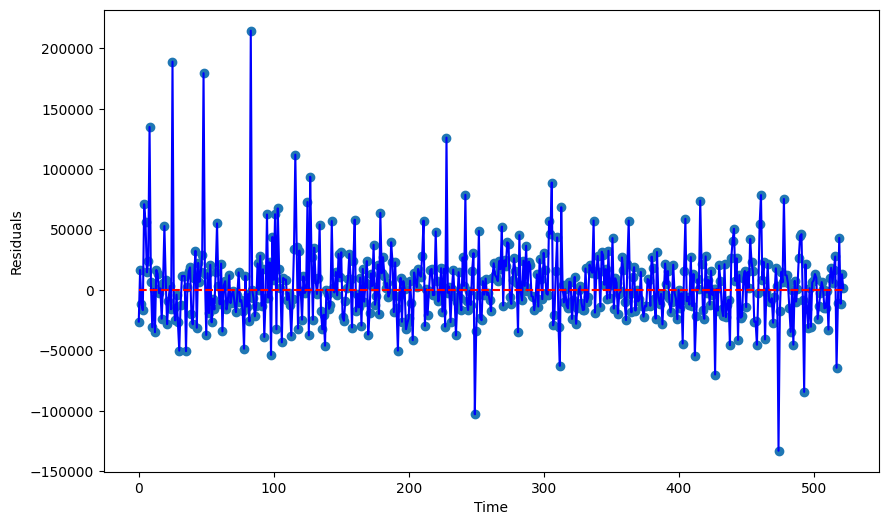

In [201]:
# Residuals vs Time - indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

This result tells us that altogether, using multiple float features produces a better model for house sale price, better than using Garage Area on its own. However, the residual analysis still shows a non-normal distribution in the residuals, showing that something is awry in the fit between the data and the model, implying linear regression may not be properly modeling the relationship between the features and the target.

## Data Visualization/Communication of Results
